In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
import pandas as pd
import numpy as np

In [3]:
df=pd.read_csv(r"D:\Irohub!\Python\Company_Analysis\cleaned_employee_data.csv")

In [4]:
df.isnull().sum()

Name         0
Team         0
Number       0
Position     0
Age          0
Height       0
Weight       0
College      0
Salary       0
Age_Group    0
dtype: int64

In [6]:
print(df.shape)
print(df.info())

(458, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 458 entries, 0 to 457
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Name       458 non-null    object 
 1   Team       458 non-null    object 
 2   Number     458 non-null    int64  
 3   Position   458 non-null    object 
 4   Age        458 non-null    int64  
 5   Height     458 non-null    int64  
 6   Weight     458 non-null    int64  
 7   College    458 non-null    object 
 8   Salary     458 non-null    float64
 9   Age_Group  458 non-null    object 
dtypes: float64(1), int64(4), object(5)
memory usage: 35.9+ KB
None


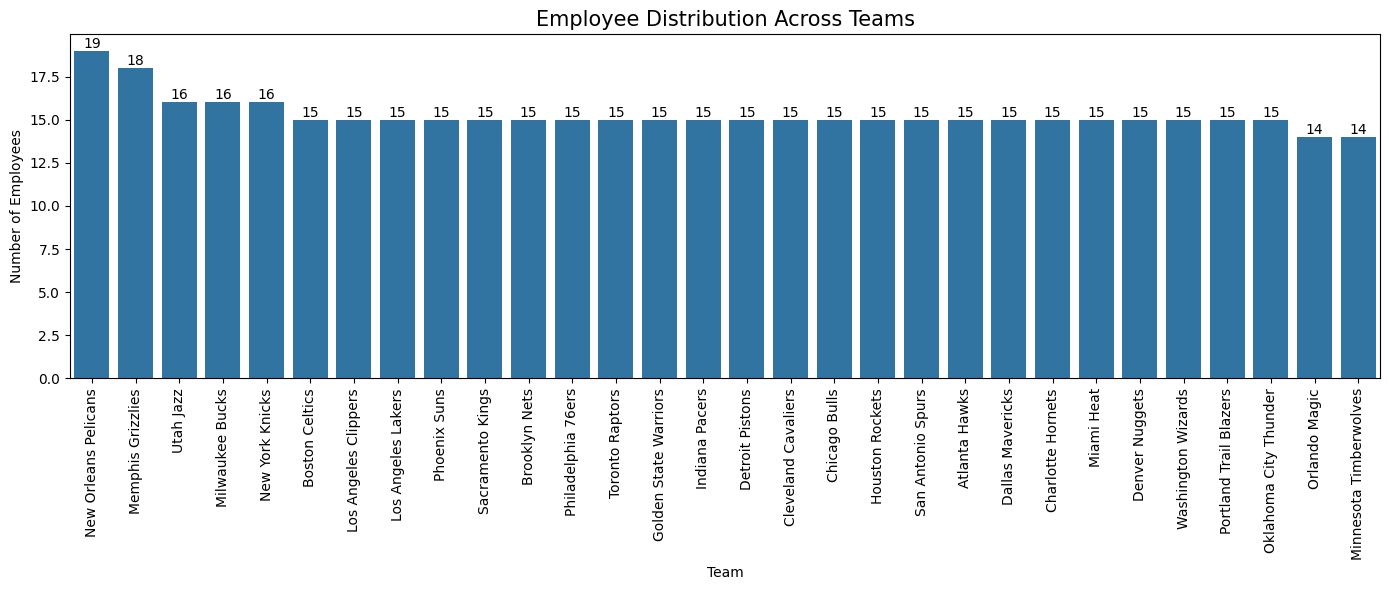

In [7]:
plt.figure(figsize=(14, 6))

ax = sns.countplot(
    data=df,
    x='Team',
    order=df['Team'].value_counts().index
)

plt.title('Employee Distribution Across Teams', fontsize=15)
plt.xlabel('Team')
plt.ylabel('Number of Employees')
plt.xticks(rotation=90)

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

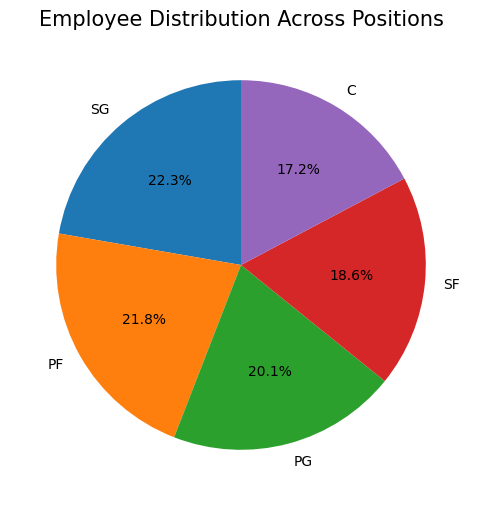

In [10]:
position_count = df['Position'].value_counts()

plt.figure(figsize=(10, 6))

plt.pie(
    position_count,
    labels=position_count.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Employee Distribution Across Positions', fontsize=15)
plt.show()

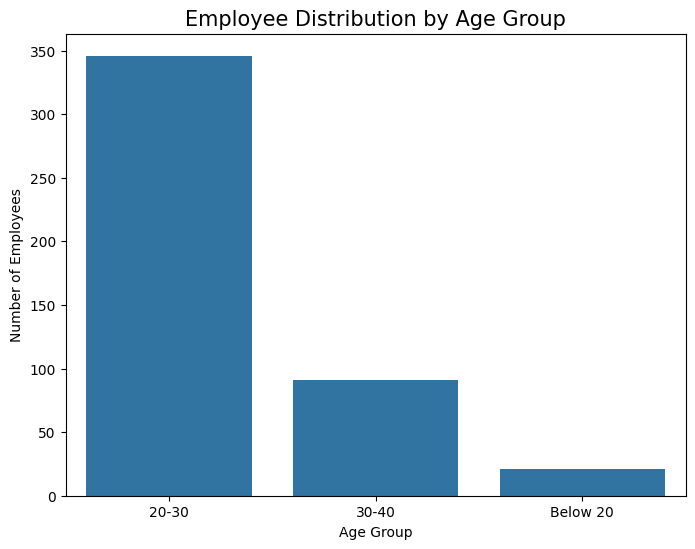

In [11]:
plt.figure(figsize=(8, 6))

sns.countplot(
    data=df,
    x='Age_Group',
    order=df['Age_Group'].value_counts().index
)

plt.title('Employee Distribution by Age Group', fontsize=15)
plt.xlabel('Age Group')
plt.ylabel('Number of Employees')

plt.show()

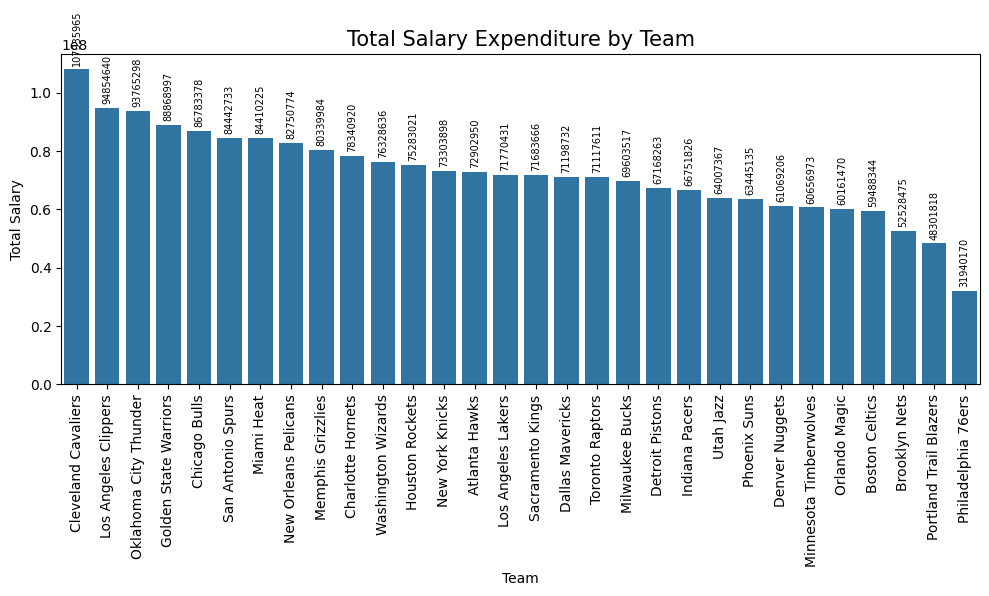

In [12]:
team_salary = df.groupby('Team')['Salary'].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=team_salary.index,
    y=team_salary.values
)

plt.title('Total Salary Expenditure by Team', fontsize=15)
plt.xlabel('Team')
plt.ylabel('Total Salary')

plt.xticks(rotation=90)

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', fontsize=7, rotation=90, padding=3)

plt.tight_layout()
plt.show()

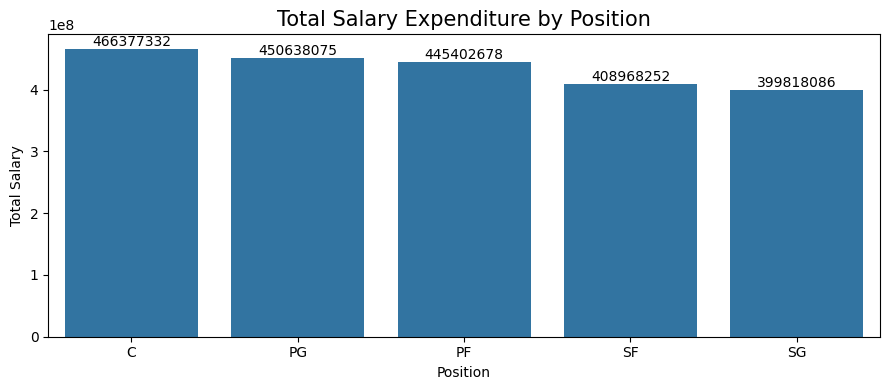

In [14]:
position_salary = df.groupby('Position')['Salary'].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 4))

ax = sns.barplot(
    x=position_salary.index,
    y=position_salary.values
)

plt.title('Total Salary Expenditure by Position', fontsize=15)
plt.xlabel('Position')
plt.ylabel('Total Salary')

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f')

plt.tight_layout()
plt.show()

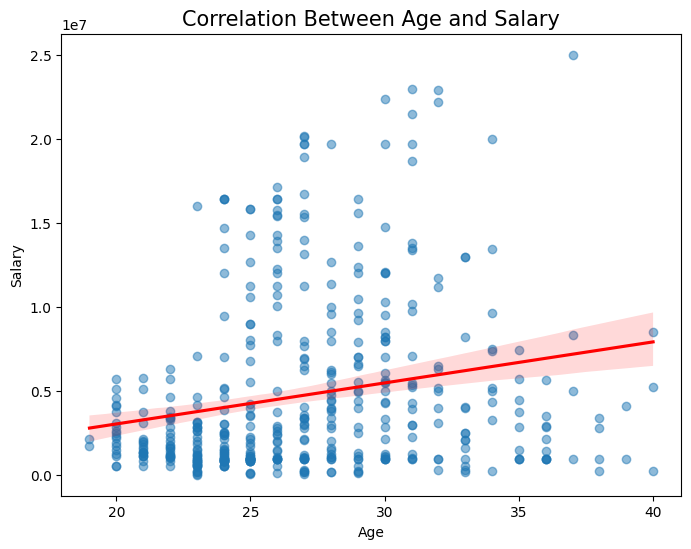

In [16]:
plt.figure(figsize=(8, 6))

sns.regplot(
    data=df,
    x='Age',
    y='Salary',
    scatter_kws={'alpha': 0.5},
    line_kws={'color': 'red'}
)

plt.title('Correlation Between Age and Salary', fontsize=15)
plt.xlabel('Age')
plt.ylabel('Salary')

plt.show()

In [17]:
# 1. Team with highest employee count
print("Largest Team:")
print(df['Team'].value_counts().idxmax())

# 2. Position with highest employee count
print("\nMost Common Position:")
print(df['Position'].value_counts().idxmax())

# 3. Predominant age group
print("\nPredominant Age Group:")
print(df['Age_Group'].value_counts().idxmax())

# 4. Team with highest salary expenditure
print("\nHighest Salary Expenditure - Team:")
print(df.groupby('Team')['Salary'].sum().idxmax())

# 5. Position with highest salary expenditure
print("\nHighest Salary Expenditure - Position:")
print(df.groupby('Position')['Salary'].sum().idxmax())

# 6. Age and salary correlation
print("\nAge-Salary Correlation:")
print(df['Age'].corr(df['Salary']))

Largest Team:
New Orleans Pelicans

Most Common Position:
SG

Predominant Age Group:
20-30

Highest Salary Expenditure - Team:
Cleveland Cavaliers

Highest Salary Expenditure - Position:
C

Age-Salary Correlation:
0.20653501683058964
